In [1]:
###INDIRECT IMPACTS FREDDY

In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [2]:
### impacts calculated
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupt_imph2.pkl', 'rb') as file:
    disrupt_imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupt_pp1.pkl', 'rb') as file:
    disrupt_pp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph1.pkl', 'rb') as file:
    imph1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/imph1_cat.pkl', 'rb') as file:
    imph1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2.pkl', 'rb') as file:
    rd2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp2.pkl', 'rb') as file:
    impp2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd1_51ens.pkl', 'rb') as file:
    rd1_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_mimpact.pkl', 'rb') as file:
    rd2_mimpact = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp3.pkl', 'rb') as file:
#    impp3 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp5.pkl', 'rb') as file:
    impp5 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp6.pkl', 'rb') as file:
    impp6 = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp7.pkl', 'rb') as file:
#    impp7 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/exp_dict.pkl', 'rb') as file:
    exp_dict = pickle.load(file)

In [3]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [4]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [5]:
from climada_petals.hazard.IMP_Indirect import (
    get_disrupted_exposures_and_ensemble,
    get_disrupted_road,
    add_geometry_to_disrupted_roads,
    add_population_and_region_to_disrupted,
    cal_nearestpop_to_infrastructure,
    calc_pp_byroaddisrup_5ens,
    assign_province_to_roads)

In [6]:
def calculate_direct_and_indirect_impacts(
    imph2, imps2, impp1, rd2_mimpact,
    gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
):
    # 1. Disrupted hospitals
    disrupted_hospitals = get_disrupted_exposures_and_ensemble(imph2, threshold=0.20, min_members=5, mode="above")
    disrupted_hospitals_copy = disrupted_hospitals.copy()
    
    # 2. Disrupted schools
    disrupted_schools = get_disrupted_exposures_and_ensemble(imps2, threshold=0.20, min_members=5, mode="above")
    disrupted_schools_copy = disrupted_schools.copy()
    
    # 3. Disrupted infrastructure (e.g. wind): add population + region
    impp1_disrupted = get_disrupted_exposures_and_ensemble(impp1, threshold=0.20, min_members=5, mode="above")
    impp1_disrupted = add_population_and_region_to_disrupted(impp1_disrupted, gdf_worldpop_MOZ.gdf, gadm_MOZ_gdf)
    impp1_disrupted_copy = impp1_disrupted.copy()
    
    # 4. Disrupted roads
    rd2_disrupted = get_disrupted_road(rd2_mimpact, threshold=0.20, min_members=5, mode="above")
    rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
    rd2_disrupted_copy = rd2_disrupted.copy()
    
    # 5. Indirect impacts
    imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_copy, impp1_disrupted_copy)
    ed2_impp1 = cal_nearestpop_to_infrastructure(disrupted_schools_copy, impp1_disrupted_copy)
    rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(rd2_disrupted_copy, impp1_disrupted_copy, radius_km=2)
    rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1, gadm_MOZ)
    
    return imph2_impp1, ed2_impp1, impp1_disrupted_copy, rd2_disrupted_impp1

In [7]:
imph2_impp1_tsd020, ed2_impp1_tsd020, impp1_disrupted_tsd020, rd2_disrupted_impp1_tsd020 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
)


 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SUCCESS: Population + NAME_1 assigned

In [8]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_tsd020, file)
with open(save_dir_pickle + 'ed2_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_tsd020, file)
with open(save_dir_pickle + 'impp1_disrupted_tsd020.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_tsd020, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_tsd020, file)

In [ ]:
#### PLOTTING 

In [9]:
rename_dict = {
    'imph2_MOZ_new_FREDDY_20230306120000': '5 days',
    'imph2_MOZ_new_FREDDY_20230307120000': '4 days',
    'imph2_MOZ_new_FREDDY_20230308120000': '3 days',
    'imph2_MOZ_new_FREDDY_20230309120000': '2 days',
    'imph2_MOZ_new_FREDDY_20230310120000': '1 day',
    'imph2_MOZ_new_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
imph2_impp1_tsd020 = {rename_dict.get(k, k): v for k, v in imph2_impp1_tsd020.items() if k in rename_dict}

In [10]:
rename_dict_impp1_disrupted = {
    'impp1_MOZ_FREDDY_20230306120000': '5 days',
    'impp1_MOZ_FREDDY_20230307120000': '4 days',
    'impp1_MOZ_FREDDY_20230308120000': '3 days',
    'impp1_MOZ_FREDDY_20230309120000': '2 days',
    'impp1_MOZ_FREDDY_20230310120000': '1 day',
    'impp1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
impp1_disrupted_tsd020  = {rename_dict_impp1_disrupted.get(k, k): v for k, v in impp1_disrupted_tsd020.items() if k in rename_dict_impp1_disrupted}

In [11]:
rename_dict_ed2 = {
    'ed2_MOZ_new_FREDDY_20230306120000': '5 days',
    'ed2_MOZ_new_FREDDY_20230307120000': '4 days',
    'ed2_MOZ_new_FREDDY_20230308120000': '3 days',
    'ed2_MOZ_new_FREDDY_20230309120000': '2 days',
    'ed2_MOZ_new_FREDDY_20230310120000': '1 day',
    'ed2_MOZ_new_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
ed2_impp1_tsd020 = {rename_dict_ed2.get(k, k): v for k, v in ed2_impp1_tsd020.items() if k in rename_dict_ed2}

In [15]:
rename_dict_rd2 = {
    '20230306120000': '5 days',
    '20230307120000': '4 days',
    '20230308120000': '3 days',
    '20230309120000': '2 days',
    '20230310120000': '1 day',
    '20230311120000': 'landfall'
}
# Rename keys using rename_dict
rd2_disrupted_impp1_tsd020 = {rename_dict_rd2.get(k, k): v for k, v in rd2_disrupted_impp1_tsd020.items() if k in rename_dict_rd2}

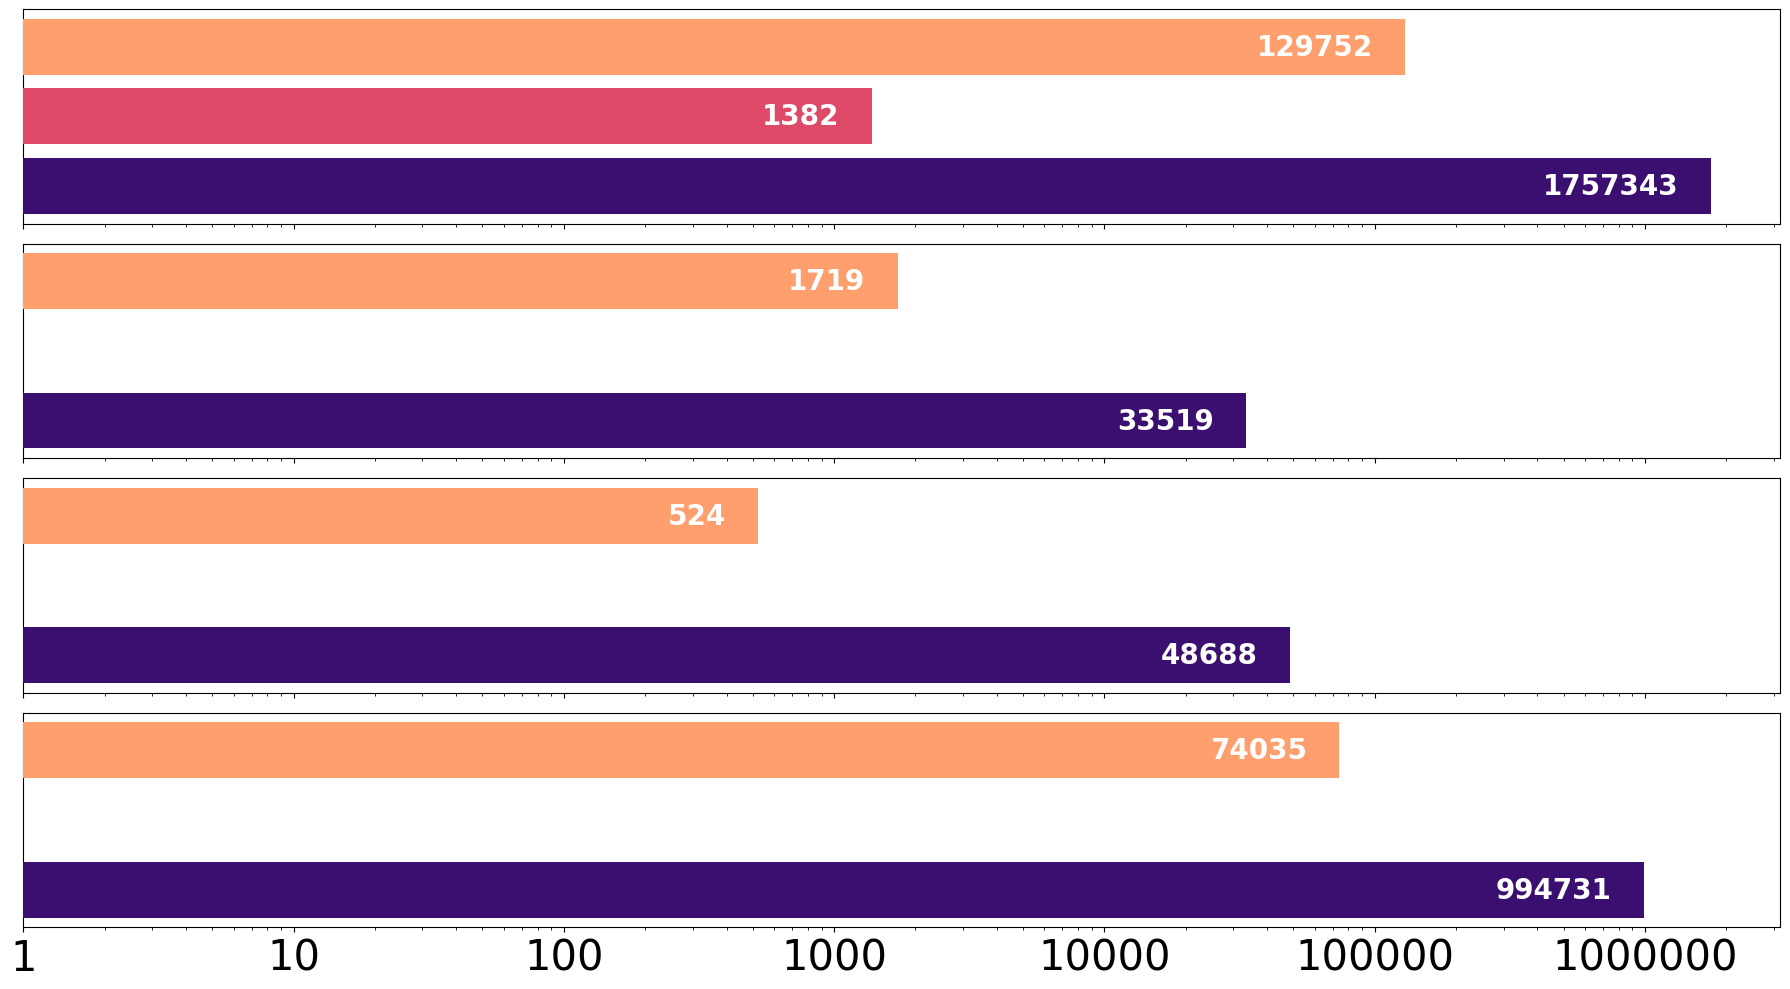

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '5 days'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d',
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_ppaff_5days.png",
    dpi=800, bbox_inches='tight'
)
plt.show()

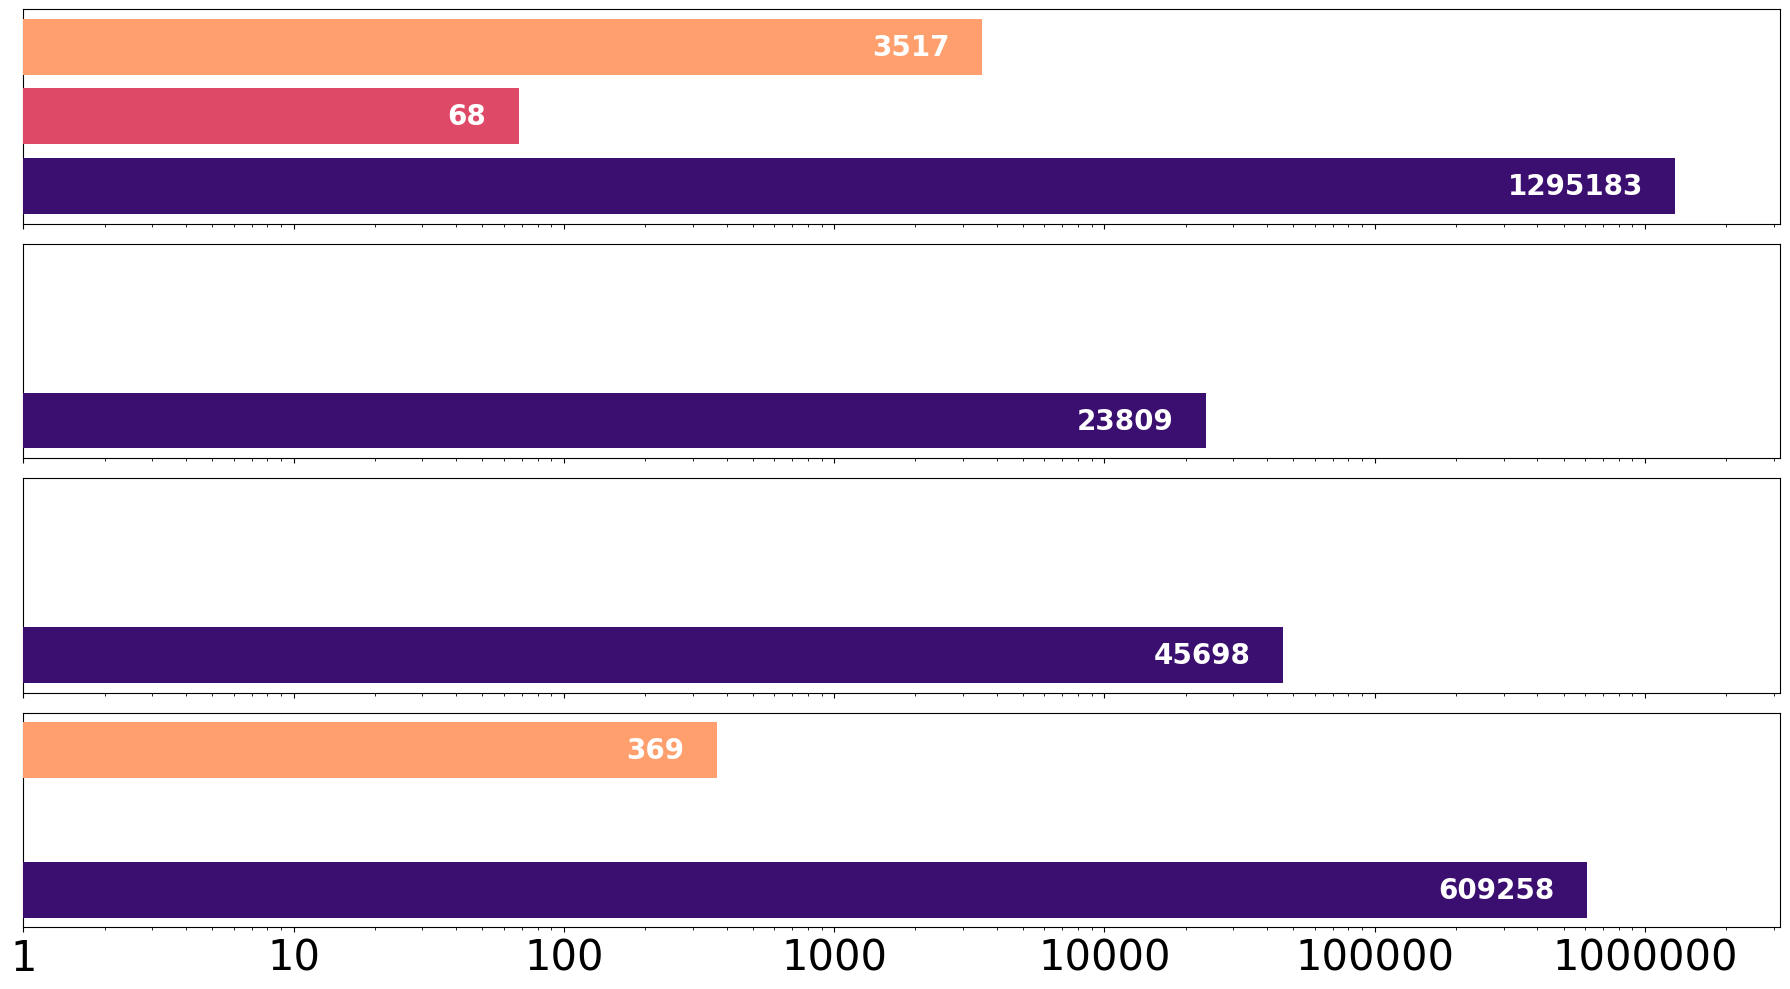

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '4 days'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':'#3b0f70','Sofala':'#de4968','Nampula':'#fe9f6d'
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_ppaff_4days.png",
    dpi=800, bbox_inches='tight'
)
plt.show()

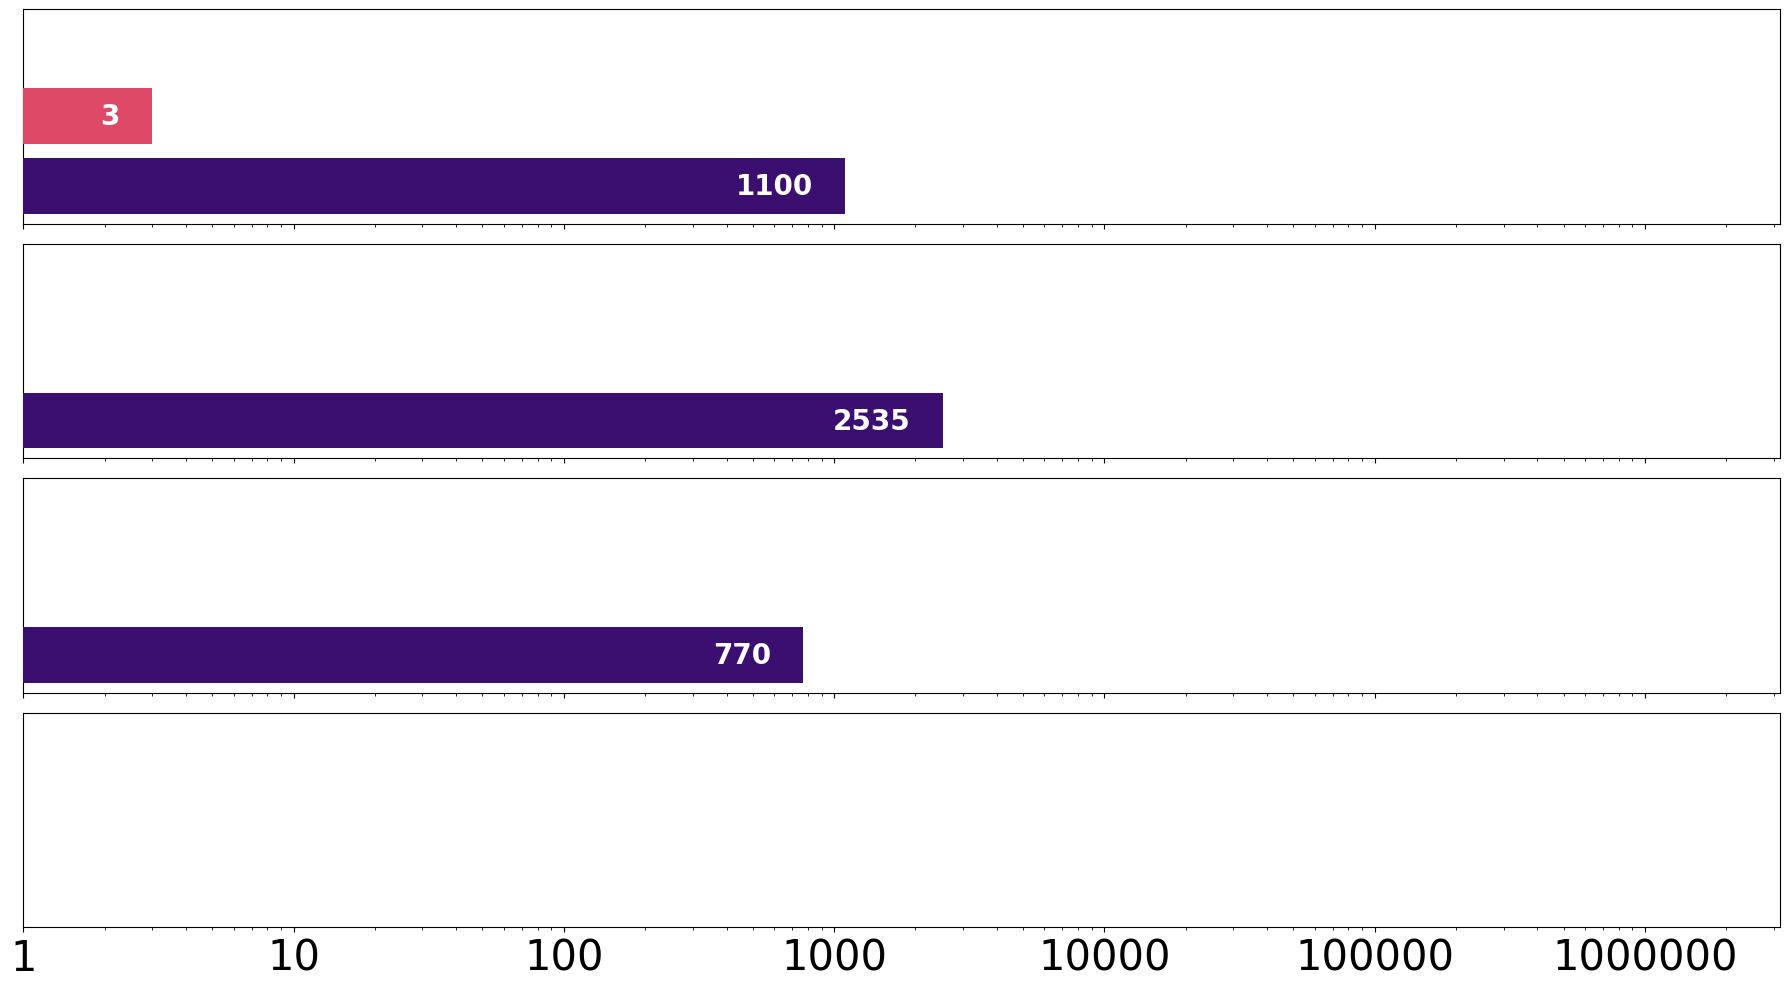

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '3 days'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':'#3b0f70','Sofala':'#de4968','Nampula':'#fe9f6d'
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_ppaff_3days.png",
    dpi=800, bbox_inches='tight'
)
plt.show()

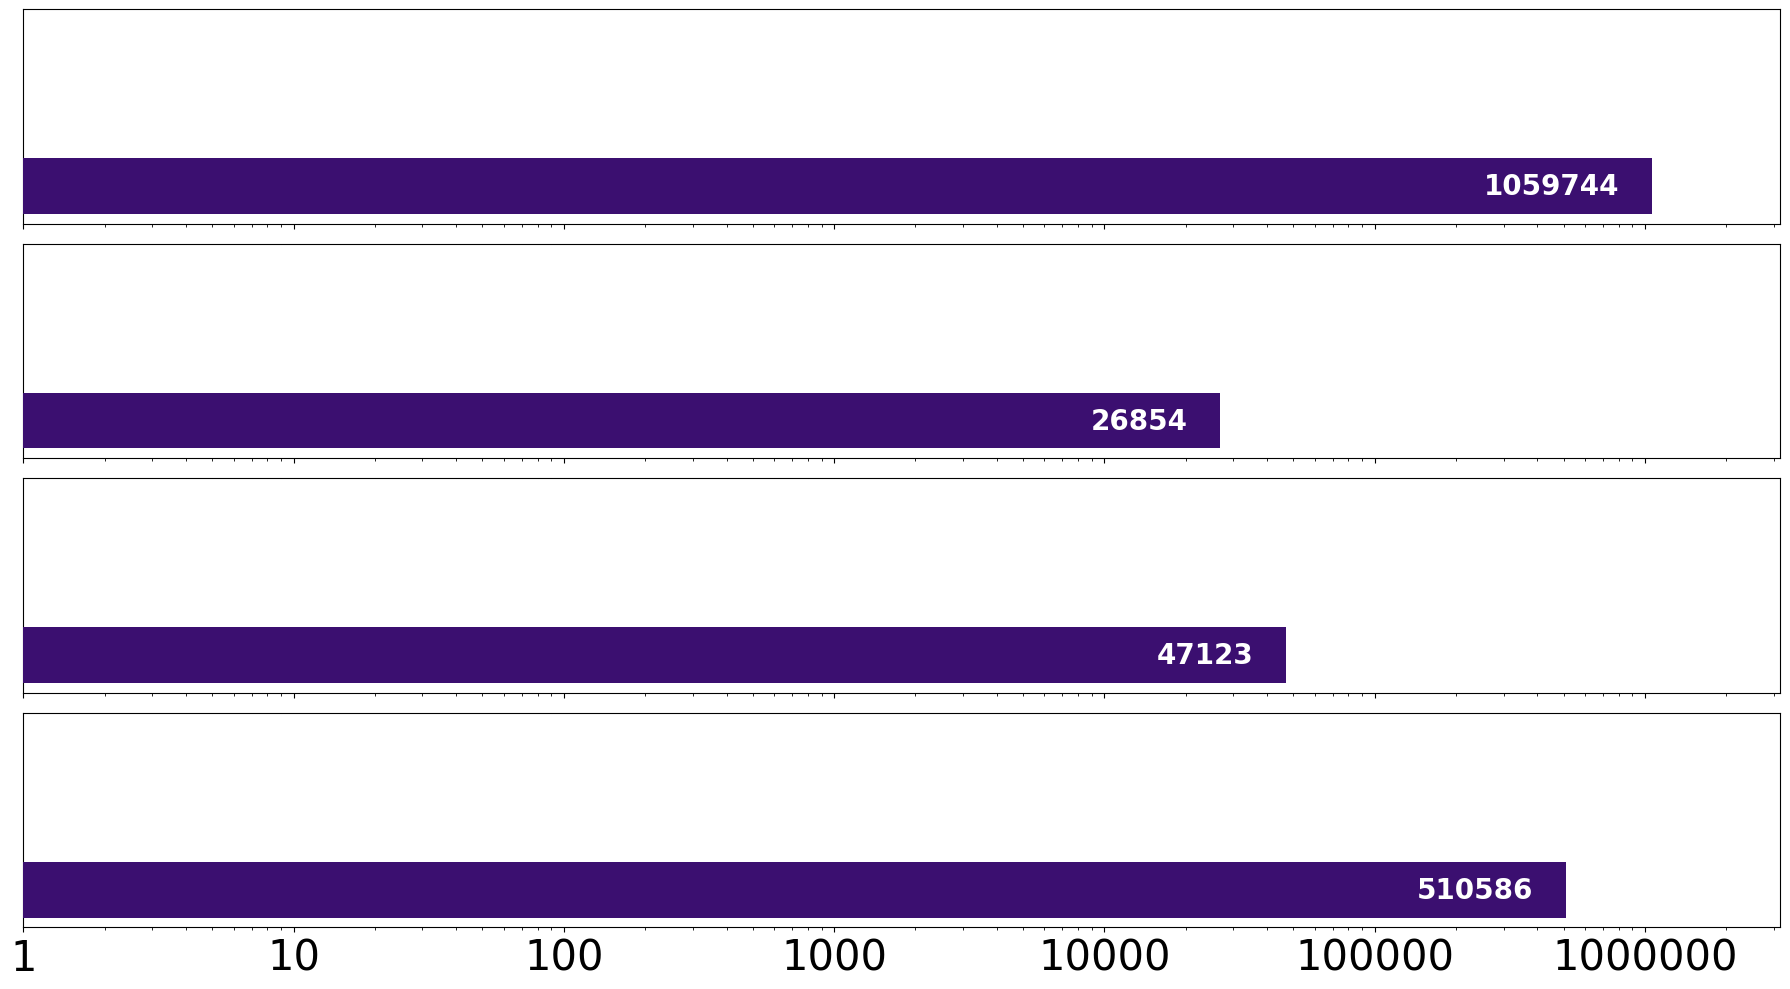

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '2 days'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':'#3b0f70','Sofala':'#de4968','Nampula':'#fe9f6d'
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_ppaff_2days.png",
    dpi=800, bbox_inches='tight'
)
plt.show()

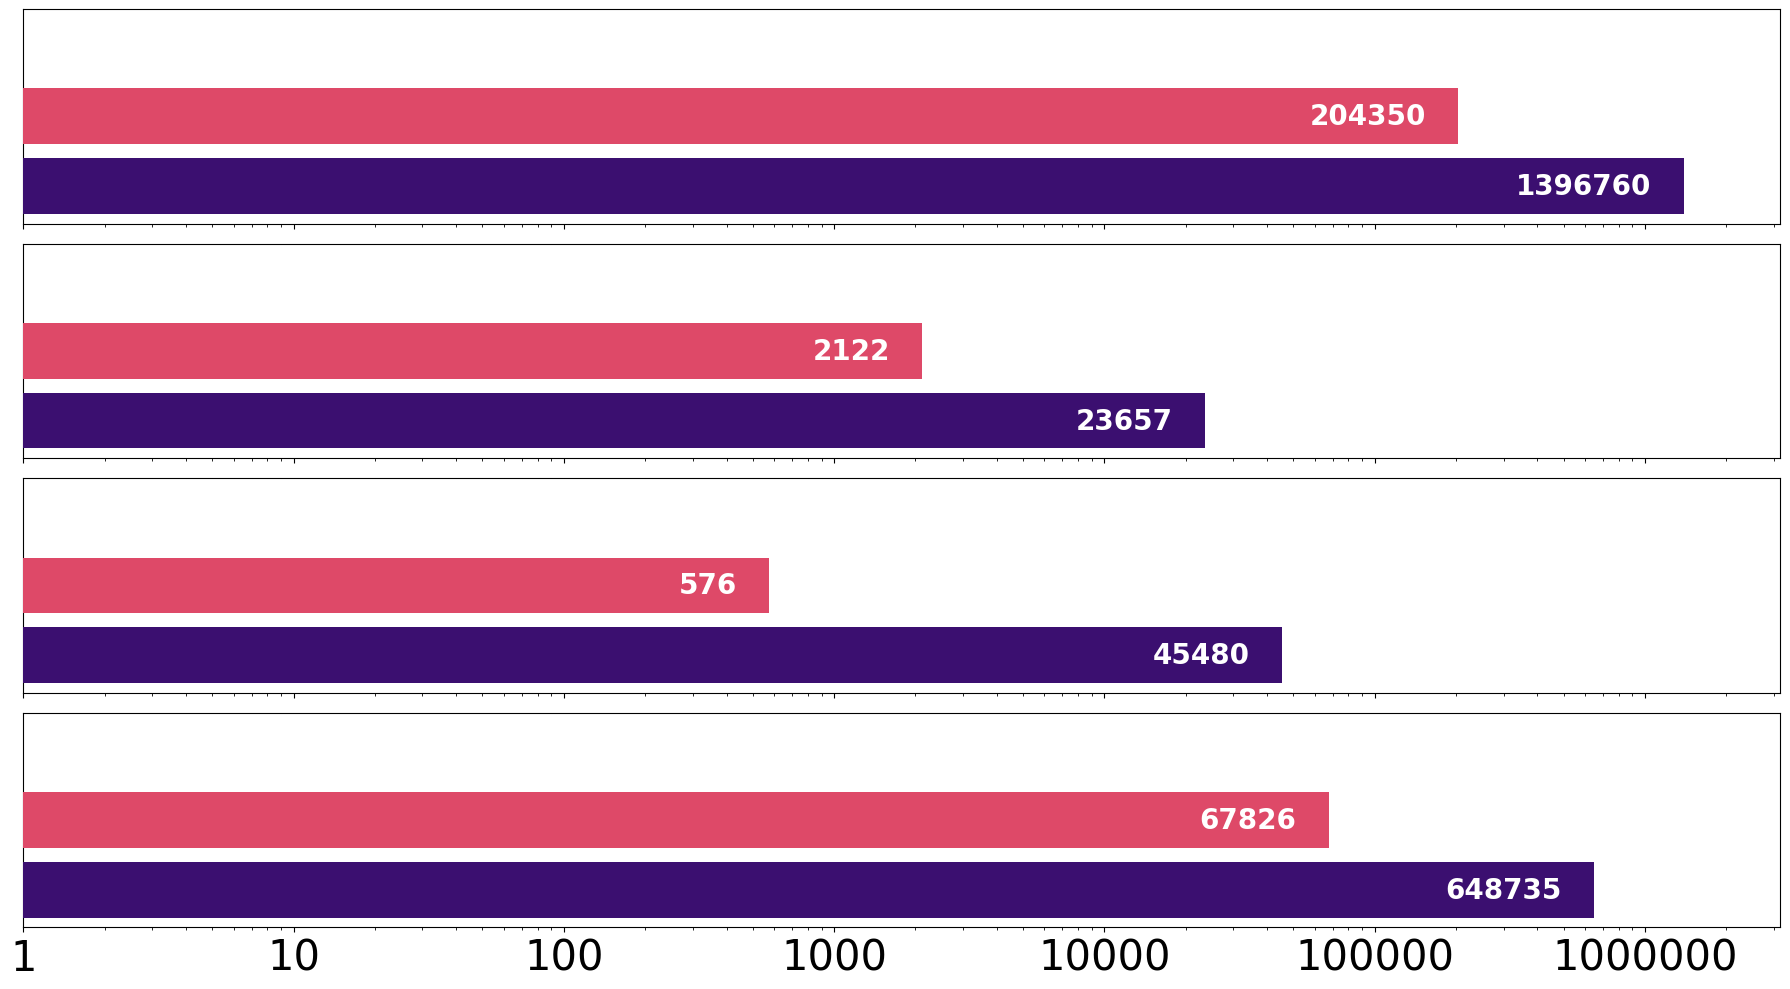

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '1 day'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':'#3b0f70','Sofala':'#de4968','Nampula':'#fe9f6d'
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_ppaff_1day.png",
    dpi=800, bbox_inches='tight'
)
plt.show()

In [ ]:
## in one single column 

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FixedLocator, LogFormatterMathtext

# ---------------- CONFIG ----------------
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']

# shared log x range and padding (half-decade past 10^6 → 10^6.5)
X_MIN, X_MAX = 1, 1_000_000
X_MAX_PAD = X_MAX * (10**0.5)   # ≈ 3.16e6

province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d'
}
provinces = list(province_colors.keys())

plt.close('all')

# ---------------- HELPERS ----------------
def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Series (index=provinces) with sums at the given lead_time."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is None:
            s = pd.Series(0.0, index=provinces)
        else:
            s = df.groupby('NAME_1')[col].sum().reindex(provinces).fillna(0.0)
    else:
        s = pd.Series(0.0, index=provinces)
    return s

def _annotate_bar(ax, value, y, color):
    if value <= 0:
        return
    # keep label safely inside padded limit
    ax.text(min(value*1.12, X_MAX_PAD*0.96), y, f"{value:.1e}",
            fontsize=18, va='center', ha='left', color=color)

# ---------------- BUILD ALL SERIES (by day) ----------------
# expects your dicts: impp1_disrupted, imph2_impp1, ed2_impp1, rd2_disrupted_impp1
day_blocks = []  # each item: list of four Series in order [direct, hosp, school, road]

for lt in lead_times:
    s_direct = _sum_by_province_for_one_lead(
        impp1_disrupted, lt, ['people','affected_pop','pp_affected','ind_pp_affected']
    )
    s_hosp   = _sum_by_province_for_one_lead(
        imph2_impp1, lt,   ['pp_affected','ind_pp_affected','affected_pop']
    )
    s_school = _sum_by_province_for_one_lead(
        ed2_impp1, lt,     ['pp_affected','ind_pp_affected','affected_pop']
    )
    s_road   = _sum_by_province_for_one_lead(
        rd2_disrupted_impp1, lt, ['pp_affected','ind_pp_affected','affected_pop']
    )
    day_blocks.append([s_direct, s_hosp, s_school, s_road])

# ---------------- PLOT (single figure, one column, shared x) ----------------
n_rows = len(lead_times) * 4
fig_height = 1.6 * n_rows  # tweak if you want more/less vertical spacing
fig, axes = plt.subplots(nrows=n_rows, ncols=1, figsize=(16, fig_height), sharex=True)

row_idx = 0
for day_i, lt in enumerate(lead_times):
    series_list = day_blocks[day_i]  # [direct, hosp, school, road]
    for s_vals in series_list:
        ax = axes[row_idx]
        for k, prov in enumerate(provinces):
            v = float(s_vals.get(prov, 0.0))
            ax.barh(k, max(v, X_MIN), color=province_colors[prov], height=0.6)
            if v > 0:
                _annotate_bar(ax, v, k, province_colors[prov])
        ax.set_yticks([])
        ax.grid(False)

        # only show bottom x tick labels on the very last row
        if row_idx < n_rows - 1:
            ax.tick_params(axis='x', which='both', labelbottom=False)
        row_idx += 1

    # add the day tag to the left of the top row of this block
    top_ax_of_block = axes[row_idx - 4]
    top_ax_of_block.text(-0.08, 1.08, lt, transform=top_ax_of_block.transAxes,
                         fontsize=25, va='bottom', ha='left', fontweight='bold')

# shared log x: ticks at decades only, and padded limit to 10^6.5
decade_ticks = [10**k for k in range(0, 7)]  # 10^0..10^6
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)
    ax.xaxis.set_major_locator(FixedLocator(decade_ticks))
    ax.xaxis.set_major_formatter(LogFormatterMathtext())

# bottom axis labels larger
axes[-1].tick_params(axis='x', labelsize=25)
fig.supxlabel("", fontsize=16)

fig.tight_layout()
# Optional save:
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_people_all_days_singlecolumn.png",
             dpi=500, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FixedLocator, LogFormatterMathtext

# ---------------- CONFIG (tweak here) ----------------
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']

X_MIN, X_MAX = 1, 1_000_000
X_MAX_PAD = X_MAX * (10**0.5)  # extend to 10^6.5 for breathing room

province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d'
}
provinces = list(province_colors.keys())

# Publication sizing
FIG_WIDTH_IN      = 7.5     # ~page width; raise to 8.5–9.0 if you prefer wider
ROW_HEIGHT_IN     = 1.35    # height per row; increase for more vertical space
BAR_HEIGHT        = 0.78    # thicker bars for print
ANNOT_FONTSIZE    = 24
TICK_FONTSIZE     = 24
DAYLABEL_FONTSIZE = 26
SPINE_LW          = 1.2
DPI_SAVE          = 800     # hi-DPI PNG; also save vector copies below

plt.close('all')

# ---------------- HELPERS ----------------
def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Series (index=provinces) with sums at the given lead_time."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is None:
            s = pd.Series(0.0, index=provinces)
        else:
            s = df.groupby('NAME_1')[col].sum().reindex(provinces).fillna(0.0)
    else:
        s = pd.Series(0.0, index=provinces)
    return s

def _annotate_bar(ax, value, y, color):
    if value <= 0:
        return
    # keep label safely inside padded limit and bump size
    ax.text(min(value*1.12, X_MAX_PAD*0.96), y, f"{value:.1e}",
            fontsize=ANNOT_FONTSIZE, va='center', ha='left', color=color)

# ---------------- BUILD ALL SERIES (by day) ----------------
day_blocks = []  # each item: [direct, hosp, school, road] for that day

for lt in lead_times:
    s_direct = _sum_by_province_for_one_lead(
        impp1_disrupted, lt, ['people','affected_pop','pp_affected','ind_pp_affected']
    )
    s_hosp   = _sum_by_province_for_one_lead(
        imph2_impp1, lt,   ['pp_affected','ind_pp_affected','affected_pop']
    )
    s_school = _sum_by_province_for_one_lead(
        ed2_impp1, lt,     ['pp_affected','ind_pp_affected','affected_pop']
    )
    s_road   = _sum_by_province_for_one_lead(
        rd2_disrupted_impp1, lt, ['pp_affected','ind_pp_affected','affected_pop']
    )
    day_blocks.append([s_direct, s_hosp, s_school, s_road])

# ---------------- PLOT (single column, shared x) ----------------
n_rows = len(lead_times) * 4
fig_height = ROW_HEIGHT_IN * n_rows + 1.25  # a little bottom margin
fig, axes = plt.subplots(nrows=n_rows, ncols=1,
                         figsize=(FIG_WIDTH_IN, fig_height),
                         sharex=True)

row_idx = 0
for day_i, lt in enumerate(lead_times):
    series_list = day_blocks[day_i]  # [direct, hosp, school, road]
    for s_vals in series_list:
        ax = axes[row_idx]

        # thicker spines for print
        for side in ("bottom", "left", "right", "top"):
            ax.spines[side].set_linewidth(SPINE_LW)

        # horizontal bars per province
        for k, prov in enumerate(provinces):
            v = float(s_vals.get(prov, 0.0))
            ax.barh(k, max(v, X_MIN), color=province_colors[prov], height=BAR_HEIGHT)
            if v > 0:
                _annotate_bar(ax, v, k, province_colors[prov])

        ax.set_yticks([])               # legend-free minimalist look
        ax.tick_params(axis='y', length=0)
        ax.grid(False)
        ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

        # hide x tick labels except on the last row
        if row_idx < n_rows - 1:
            ax.tick_params(axis='x', which='both', labelbottom=False)

        row_idx += 1

    # add the day tag to the left of the top row of this block
    #top_ax = axes[row_idx - 4]
    #top_ax.text(-0.08, 1.08, lt, transform=top_ax.transAxes,
    #            fontsize=DAYLABEL_FONTSIZE, va='bottom', ha='left', fontweight='bold')

# shared log x: decades + padded limit to 10^6.5
decade_ticks = [10**k for k in range(0, 7)]  # 10^0..10^6
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)
    ax.xaxis.set_major_locator(FixedLocator(decade_ticks))
    ax.xaxis.set_major_formatter(LogFormatterMathtext())

# bottom label only (shared axis)
axes[-1].set_xlabel("", fontsize=TICK_FONTSIZE+2, labelpad=8)

plt.subplots_adjust(left=0.12, right=0.98, top=0.98, bottom=0.07, hspace=0.35)
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_people_all_days_singlecolumn.png",
             dpi=500, bbox_inches='tight')
plt.show()

In [ ]:
## Legend

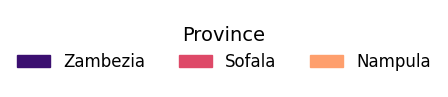

In [95]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Province colors (same as in main plot)
province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d'
}

# Create legend handles
legend_handles = [Patch(color=color, label=province) for province, color in province_colors.items()]

# Create standalone legend figure
fig_legend = plt.figure(figsize=(4, 1))  # Adjust size as needed
plt.legend(handles=legend_handles, loc='center', ncol=len(province_colors),
           title='Province', title_fontsize=14, fontsize=12, frameon=False)

# Remove axes
plt.axis('off')

# Save the legend
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/legend_provinces.png",
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
###### Infrastructure but all data in numbers and scale in log 

In [93]:
## then we will calculate it when we use categorization 1 cat 
### Testing 

In [ ]:
### ADDITIONAL CALCULATIONS!!!! 

In [94]:
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/imph1_cat.pkl', 'rb') as file:
    imph1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/ed1_cat.pkl', 'rb') as file:
    ed1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/impp1_cat.pkl', 'rb') as file:
    impp1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/rd1_51ens_cat.pkl', 'rb') as file:
    rd1_51ens_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/exp_dict_cat.pkl', 'rb') as file:
    exp_dict_cat = pickle.load(file)

In [123]:
### 
def calculate_direct_and_indirect_impacts(
    imph2, imps2, impp1, rd2_51ens,
    exp_rd2_gdf, gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
):
    # 1. Disrupted hospitals
    disrupted_hospitals = get_disrupted_exposures_and_ensemble(imph2, threshold=0.20, min_members=5, mode="above")
    disrupted_hospitals_copy = disrupted_hospitals.copy()
    
    # 2. Disrupted schools
    disrupted_schools = get_disrupted_exposures_and_ensemble(imps2, threshold=0.20, min_members=5, mode="above")
    disrupted_schools_copy = disrupted_schools.copy()
    
    # 3. Disrupted infrastructure (e.g. wind): add population + region
    impp1_disrupted = get_disrupted_exposures_and_ensemble(impp1, threshold=0.20, min_members=5, mode="above")
    impp1_disrupted = add_population_and_region_to_disrupted(impp1_disrupted, gdf_worldpop_MOZ.gdf, gadm_MOZ_gdf)
    impp1_disrupted_copy = impp1_disrupted.copy()
    
    # 4. Disrupted roads
    rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_rd2_gdf)
    mimpact_cols_scale(rd2_mimpact, 500.0)
    rd2_disrupted = get_disrupted_road(rd2_mimpact, threshold=0.20, min_members=5, mode="above")
    rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
    rd2_disrupted_copy = rd2_disrupted.copy()
    
    # 5. Indirect impacts
    imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_copy, impp1_disrupted_copy)
    ed2_impp1 = cal_nearestpop_to_infrastructure(disrupted_schools_copy, impp1_disrupted_copy)
    rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(rd2_disrupted_copy, impp1_disrupted_copy, radius_km=2)
    rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1, gadm_MOZ)
    
    return imph2_impp1, ed2_impp1, impp1_disrupted_copy, rd2_disrupted_impp1

In [124]:
imph1_impp1_cat, ed1_impp1_cat, impp1_disrupted_copy_cat, rd1_disrupted_impp1_cat = calculate_direct_and_indirect_impacts(
    imph1_cat, ed1_cat, impp1, rd1_51ens_cat,
    exp_dict_cat['exp_rd1_MOZ'].gdf, gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
)

/scratch/tmp.33912107.gespejo/ipykernel_184098/2390560494.py:28: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gadm_MOZ_gdf.geometry.centroid


 222412 unmatched points in impp1_MOZ_FREDDY_20230306120000 — assigning nearest NAME_1 using KDTree...
 178720 unmatched points in impp1_MOZ_FREDDY_20230307120000 — assigning nearest NAME_1 using KDTree...
 58099 unmatched points in impp1_MOZ_FREDDY_20230308120000 — assigning nearest NAME_1 using KDTree...
 56150 unmatched points in impp1_MOZ_FREDDY_20230309120000 — assigning nearest NAME_1 using KDTree...
 57574 unmatched points in impp1_MOZ_FREDDY_20230310120000 — assigning nearest NAME_1 using KDTree...
 10333 unmatched points in impp1_MOZ_FREDDY_20230311120000 — assigning nearest NAME_1 using KDTree...

🔍 Starting nearest population match for 6 lead times...

➡️  Processing: imph1_MOZ_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230306120000

➡️  Processing: imph1_MOZ_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230307120000

➡️  Proces

In [126]:
imph1_impp1_cat_dict_rename = {
    'imph1_MOZ_FREDDY_20230306120000': '5 days',
    'imph1_MOZ_FREDDY_20230307120000': '4 days',
    'imph1_MOZ_FREDDY_20230308120000': '3 days',
    'imph1_MOZ_FREDDY_20230309120000': '2 days',
    'imph1_MOZ_FREDDY_20230310120000': '1 day',
    'imph1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
imph1_impp1_cat = {imph1_impp1_cat_dict_rename.get(k, k): v for k, v in imph1_impp1_cat.items() if k in imph1_impp1_cat_dict_rename}

In [127]:
ed1_impp1_cat_dict_rename = {
    'ed1_MOZ_FREDDY_20230306120000': '5 days',
    'ed1_MOZ_FREDDY_20230307120000': '4 days',
    'ed1_MOZ_FREDDY_20230308120000': '3 days',
    'ed1_MOZ_FREDDY_20230309120000': '2 days',
    'ed1_MOZ_FREDDY_20230310120000': '1 day',
    'ed1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
ed1_impp1_cat = {ed1_impp1_cat_dict_rename.get(k, k): v for k, v in ed1_impp1_cat.items() if k in ed1_impp1_cat_dict_rename}

In [128]:
impp1_cat_dict_rename = {
    'impp1_MOZ_FREDDY_20230306120000': '5 days',
    'impp1_MOZ_FREDDY_20230307120000': '4 days',
    'impp1_MOZ_FREDDY_20230308120000': '3 days',
    'impp1_MOZ_FREDDY_20230309120000': '2 days',
    'impp1_MOZ_FREDDY_20230310120000': '1 day',
    'impp1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
impp1_disrupted_copy_cat = {impp1_cat_dict_rename.get(k, k): v for k, v in impp1_disrupted_copy_cat.items() if k in impp1_cat_dict_rename}

In [129]:
rd1_impp1_cat_dict_rename = {
    '20230306120000': '5 days',
    '20230307120000': '4 days',
    '20230308120000': '3 days',
    '20230309120000': '2 days',
    '20230310120000': '1 day',
    '20230311120000': 'landfall'
}
# Rename keys using rename_dict
rd1_disrupted_impp1_cat = {rd1_impp1_cat_dict_rename.get(k, k): v for k, v in rd1_disrupted_impp1_cat.items() if k in rd1_impp1_cat_dict_rename}

In [130]:
### Results with categories calculated for the impacts 

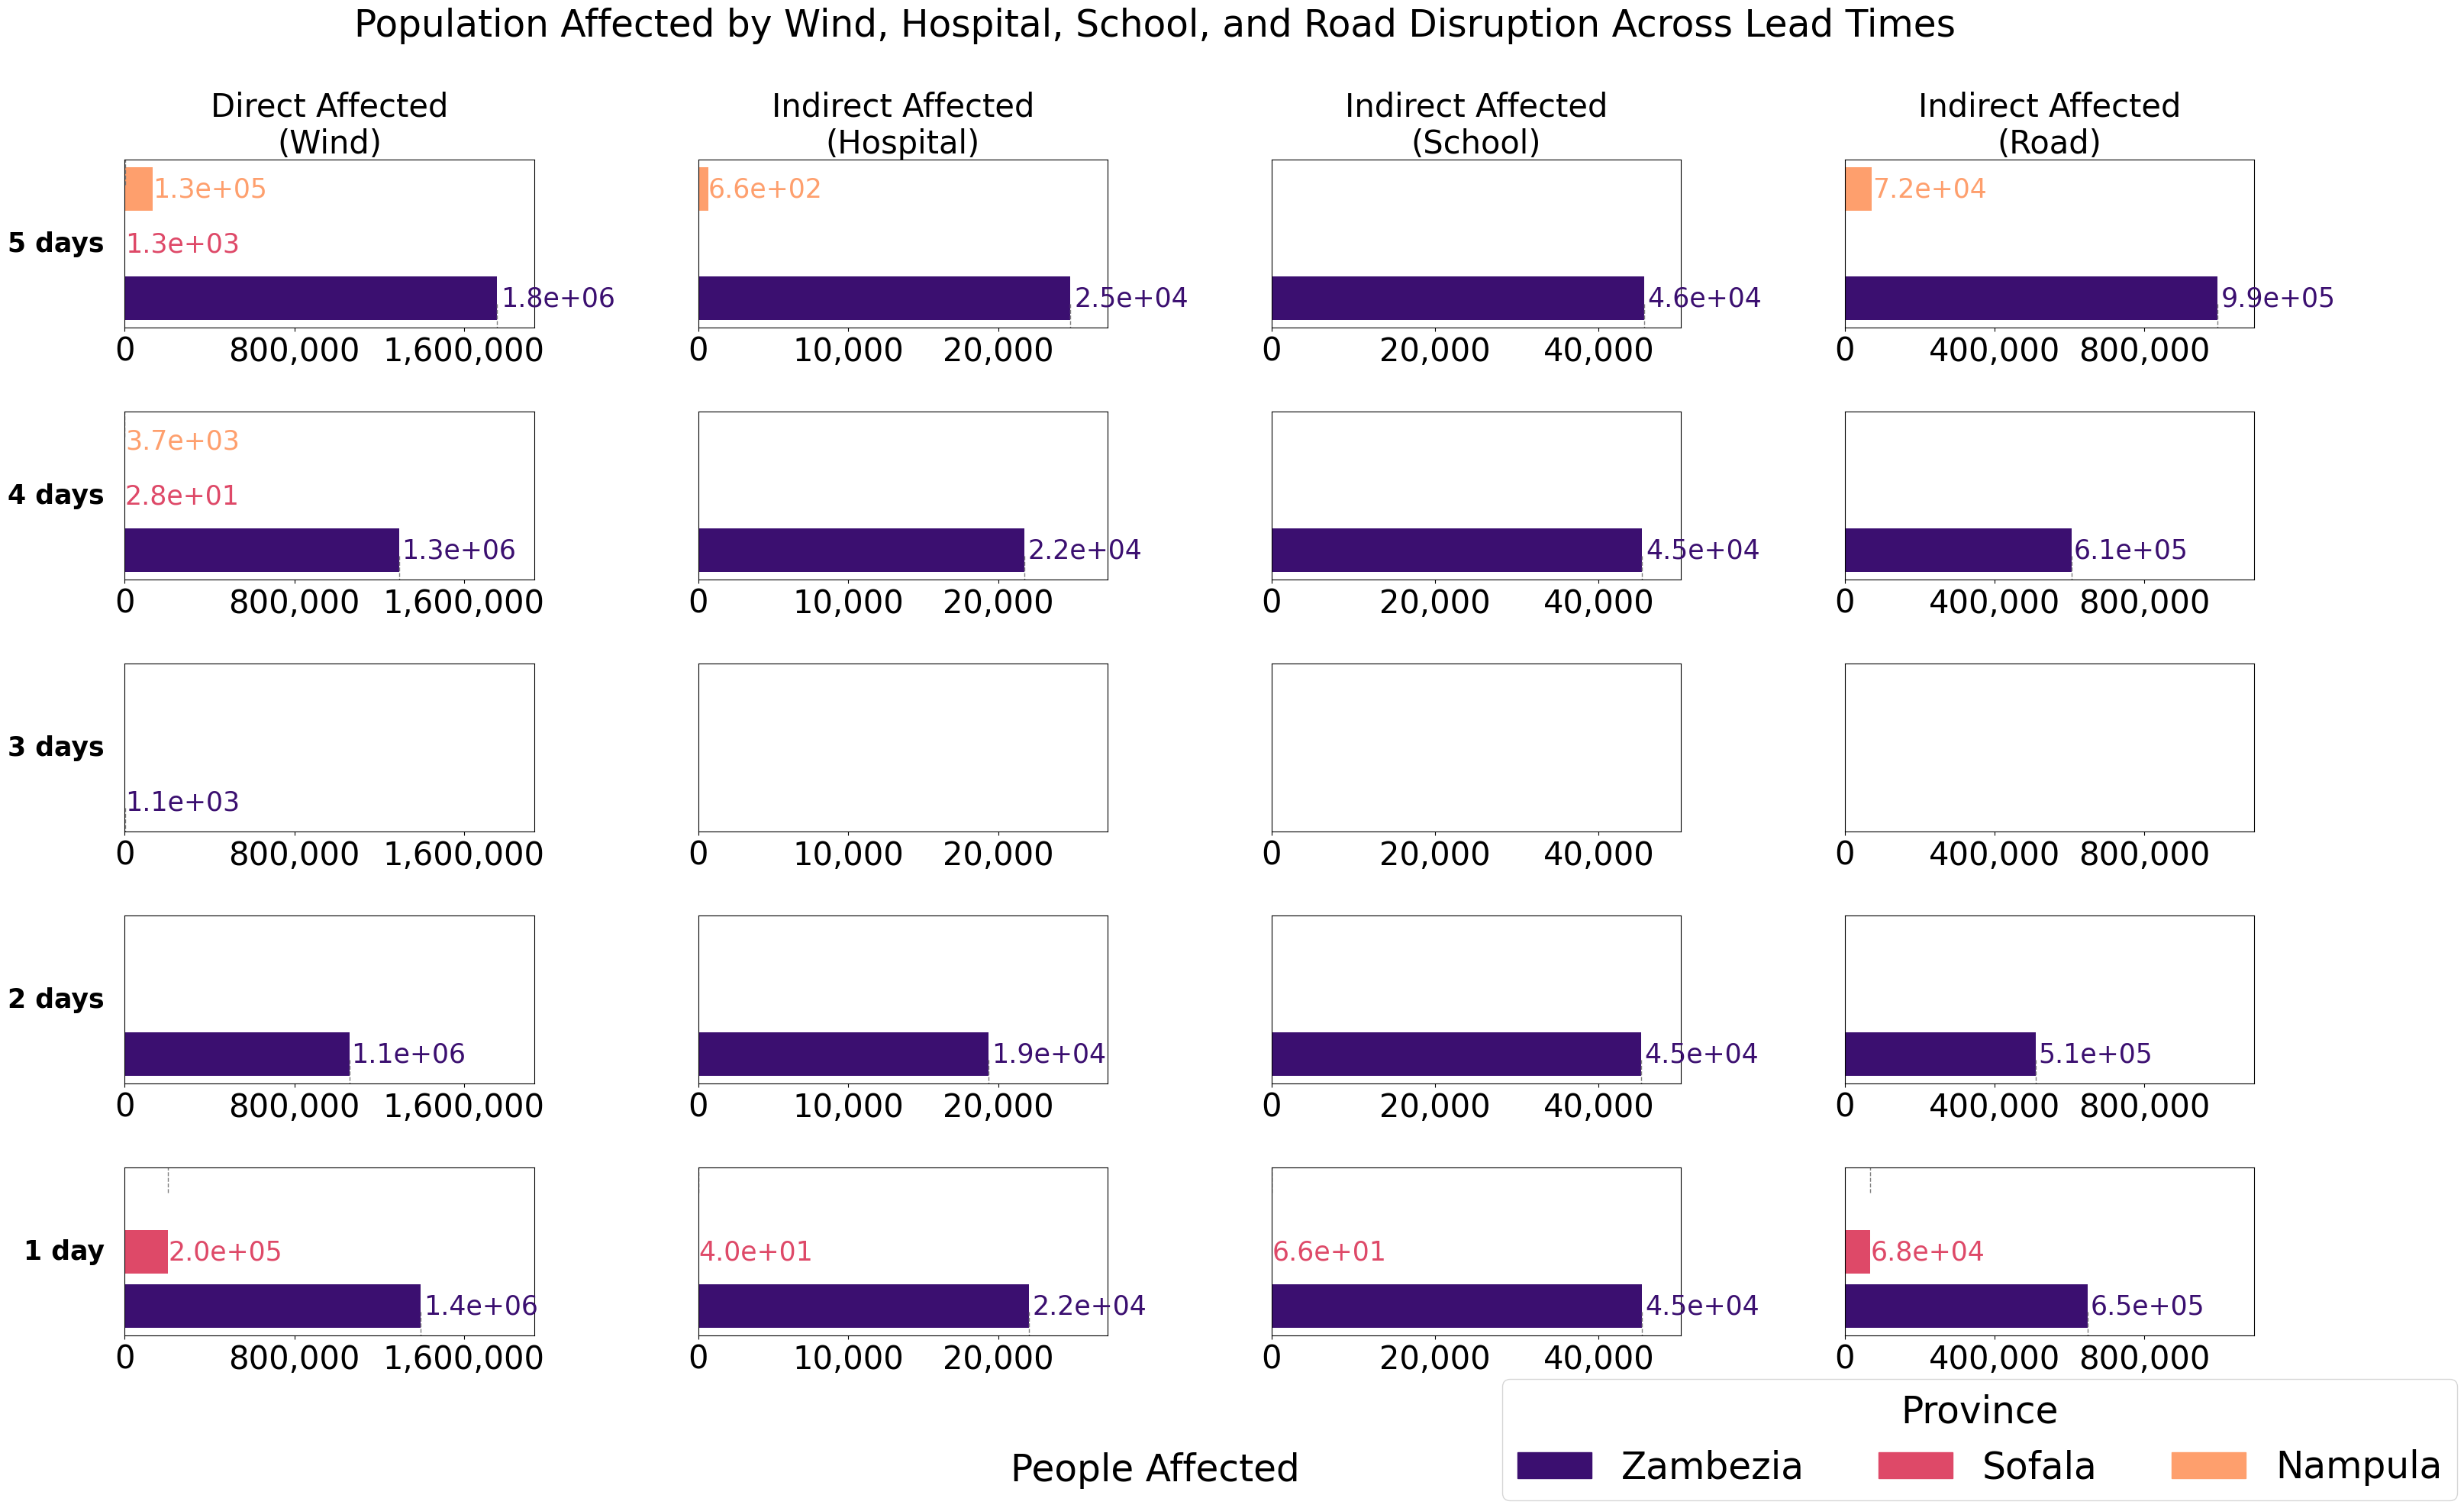

In [131]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']
province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d'
}
provinces = list(province_colors.keys())

# Initialize data structures
leadtime_province_h1_cat = {}
leadtime_province_ed1_cat = {}
leadtime_province_p1_cat = {}
leadtime_province_rd1_cat = {}

# Aggregate safely per lead time and province
for lt in lead_times:
    # Wind (direct)
    if lt in impp1_disrupted_copy_cat:
        df_p1_cat = impp1_disrupted_copy_cat[lt]
        leadtime_province_p1_cat[lt] = df_p1_cat.groupby('NAME_1')['people'].sum()
    else:
        leadtime_province_p1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # Hospital
    if lt in imph1_impp1_cat:
        df_h1_cat = imph1_impp1_cat[lt]
        leadtime_province_h1_cat[lt] = df_h1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_h1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # School
    if lt in ed1_impp1_cat:
        df_ed1_cat = ed1_impp1_cat[lt]
        leadtime_province_ed1_cat[lt] = df_ed1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_ed1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # Road
    if lt in rd1_disrupted_impp1_cat:
        df_rd1_cat = rd1_disrupted_impp1_cat[lt]
        leadtime_province_rd1_cat[lt] = df_rd1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_rd1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

# Convert to DataFrames and fill missing entries
df_h1_cat = pd.DataFrame(leadtime_province_h1_cat).T.fillna(0)
df_ed1_cat = pd.DataFrame(leadtime_province_ed1_cat).T.fillna(0)
df_p1_cat = pd.DataFrame(leadtime_province_p1_cat).T.fillna(0)
df_rd1_cat = pd.DataFrame(leadtime_province_rd1_cat).T.fillna(0)

# Create figure and GridSpec
fig = plt.figure(figsize=(36, 20))
gs = gridspec.GridSpec(nrows=len(lead_times), ncols=4, wspace=0.4, hspace=0.5)
axes = np.empty((len(lead_times), 4), dtype=object)

# Draw helper
def draw_bar_end_line(ax, value, y, color):
    ax.axvline(x=value, ymin=y-0.15, ymax=y+0.15, color='gray', linestyle='--', linewidth=1)
    ax.text(value * 1.01, y, f"{value:.1e}", fontsize=25, va='center', ha='left', color=color)

for i, lt in enumerate(lead_times):
    wind_vals = df_p1_cat.loc[lt]
    hosp_vals = df_h1_cat.loc[lt]
    school_vals = df_ed1_cat.loc[lt]
    road_vals = df_rd1_cat.loc[lt]

    for col, (vals, title, maxval) in enumerate([
        (wind_vals,   "Direct Affected\n(Wind)",    df_p1_cat.values.max()),
        (hosp_vals,   "Indirect Affected\n(Hospital)", df_h1_cat.values.max()),
        (school_vals, "Indirect Affected\n(School)",   df_ed1_cat.values.max()),
        (road_vals,   "Indirect Affected\n(Road)",     df_rd1_cat.values.max())
    ]):
        ax = fig.add_subplot(gs[i, col])
        for j, prov in enumerate(provinces):
            val = vals.get(prov, 0)
            ax.barh(j, val, color=province_colors[prov])
            if val > 0:
                draw_bar_end_line(ax, val, j, province_colors[prov])

        ax.set_xlim(0, maxval * 1.1 if maxval > 0 else 1)
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis='x', labelsize=30)
        ax.set_yticks([])
        ax.grid(False)
        if i == 0:
            ax.set_title(title, fontsize=30)
        if col == 0:
            ax.text(-0.05, 0.5, lt, transform=ax.transAxes,
                    fontsize=25, va='center', ha='right', fontweight='bold')
        axes[i, col] = ax

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=35, fontsize=35, bbox_to_anchor=(0.8, -0.01))

# Axis and title
fig.supxlabel("People Affected", fontsize=35)
fig.suptitle("Population Affected by Wind, Hospital, School, and Road Disruption Across Lead Times", fontsize=35)

fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_people_FREDDY_cat", dpi=800, bbox_inches='tight')
plt.show()